## Nonradiative Transition Rates in the NV- in Diamond

In [1]:
%matplotlib widget
import os, sys
path = os.getcwd()
os.chdir(path)
sys.path.append('/home/svillani/Programs/pypl/pypl/') 
import hr_nonrad_solver

import numpy as np
from scipy import constants
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size': 12})

blue = '#4285F4'
red = '#DB4437'
deep_violet = '#9D80B8'
soft_coral = '#F3B1BA'
goldenrod_yellow = '#EBD68F'
emerald_green = '#02A650'

eV = constants.eV
amu = constants.physical_constants['atomic mass constant'][0]
hbar = constants.hbar
ry2eV = 13.6057039763
bohr2ang = 0.529177249

## 1. Compute the electron-phonon coupling matrix element using the NAC vector obtained from TDDFT calculations.

To compute the electron-phonon coupling matrix element for the ${}^1\!A_1 \to {}^1\!E$ nonradiative transition of the $\text{NV}^-$ center in diamond, we require the NAC vector between the ${}^1\!A_1$ and ${}^1\!E$ states and the phonon frequencies and eigenmodes evaluated at the equilibrium geometry of the ${}^1\!A_1$ state.

The NAC vector can be computed from a spin-flip time-dependent density functional theory (TDDFT) calculation using the [WEST](https://west-code.org/) code. Input and pseudopotential files for this calculation are provided in the `pbe/1A1` directory. The relevant output file is `pbe/1A1/west.wbse.save/wbse.json`, which contains the NAC vector between the ${}^1\!A_1$ and ${}^1\!E$ states evaluated at the ${}^1\!A_1$ geometry.

The equilibrium coordinates of the ${}^1\!A_1$ state can be obtained from a spin-flip TDDFT calculation using the [WEST](https://west-code.org/) code. Input and pseudopotential files for this calculation are provided in the `pbe/1A1` directory. The relevant output file is `pbe/1A1/pwscf.xml`, which contains the optimized atomic positions. The excited state forces of the ${}^1\!E$ state at the ${}^1\!A_1$ geometry are stored in `pbe/1A1/west.wbse.save/wbse.json`.

Phonon frequencies and eigenmodes at the ${}^1\!A_1$ equilibrium geometry are computed using the frozen-phonon approach with the [Phonopy](https://phonopy.github.io/phonopy/) package. The resulting phonon frequencies and eigenmodes are stored in `pbe/1A1_eigenvectors.dat`.

We also need to provide the energy of the initial state (${}^1\!A_1$) and the final state (${}^1\!E$) in at the ${}^1\!A_1$ geometry, together with the adiabatic transition energy.

In the spin-flip TDDFT calculation, the ${}^1\!A_1$ state is state 4, and the ${}^1\!E$ states are states 2 and 3. At the optimized geometry of the ${}^1\!A_1$ state, the ${}^1\!E$ states are doubly degenerate. We will compute the electron-phonon coupling matrix elements between state 4 and both state 2 and state 3.

In [2]:
from hr_nonrad_solver import hr_nonrad_solver
from utils import *

# phonons are computed at the pbe level of theory
state_4_phonon_file = 'pbe/1A1_ph_mesh.hdf5'

# PBE results
nac_state_24_file_pbe = 'pbe/1A1/west.wbse.save/wbse.json'
nac_state_34_file_pbe = 'pbe/1A1/west.wbse.save/wbse_1.json'
state_4_pwscf_file_pbe = 'pbe/1A1/pwscf.xml'
state_2_forces_file_pbe = 'pbe/1A1/west.wbse.save/wbse.json'
state_3_forces_file_pbe = 'pbe/1A1/west.wbse.save/wbse_1.json'

# Rydberg to eV
state_2_energy_pbe = 0.043302206212159446 * ry2eV
state_4_energy_pbe = 0.10246445187671975 * ry2eV

# DDH results
nac_state_24_file_ddh = 'ddh/1A1/west.wbse.save/wbse.json' 
nac_state_34_file_ddh = 'ddh/1A1/west.wbse.save/wbse_1.json'
state_4_pwscf_file_ddh = 'ddh/1A1/pwscf.xml' 
state_2_forces_file_ddh = 'ddh/1A1/west.wbse.save/wbse.json'  
state_3_forces_file_ddh = 'ddh/1A1/west.wbse.save/wbse_1.json'

# Rydberg to eV
state_2_energy_ddh = 0.058799344315802048 * ry2ev # TDDFT
state_4_energy_ddh = 0.15216704089017688 * ry2ev # TDDFT

# adiabatic transition energy (meV)
adiabatic_energy = 1190 # Experimental value
adiabatic_energy_pbe = 1319-448 # with PBE
adiabatic_energy_ddh = 1957-560 # with DDH

In [3]:
def parse_forces_from_wbse_json(filename):
    import json
    with open(filename, 'r') as f:
        data = json.load(f)
    forces = np.array(data['output']['forces']['forces_corrected']).reshape(-1, 3)
    # Ry/bohr to eV/Angstrom
    forces *= (ry2eV / bohr2ang)
    return forces

def parse_nac_from_wbse_json(filename):
    import json
    with open(filename, 'r') as f:
        data = json.load(f)
    nac = np.array(data['output']['nac_vec']['eenac_corrected']).reshape(-1, 3)
    # 1/bohr to 1/Angstrom
    nac /= bohr2ang
    return nac

We can parse the NAC vector from the WEST output file. Since the ${}^1\!E$ state is doubly degenerate, we parse the NAC vectors separately for each state:

In [4]:
nac_vec_24_pbe = parse_nac_from_wbse_json(nac_state_24_file_pbe)
print(nac_vec_24_pbe.shape)
print(nac_vec_24_pbe[-5:])
print()

nac_vec_34_pbe = parse_nac_from_wbse_json(nac_state_34_file_pbe)
print(nac_vec_34_pbe.shape)
print(nac_vec_34_pbe[-5:])
print()

nac_vec_24_ddh = parse_nac_from_wbse_json(nac_state_24_file_ddh)
print(nac_vec_24_ddh.shape)
print(nac_vec_24_ddh[-5:])
print()

nac_vec_34_ddh = parse_nac_from_wbse_json(nac_state_34_file_ddh)
print(nac_vec_34_ddh.shape)
print(nac_vec_34_ddh[-5:])
print()

(215, 3)
[[ 0.05611101 -0.08982402 -0.06312904]
 [-0.05795386  0.03954737  0.00309305]
 [-0.00427369  0.08582362  0.0501007 ]
 [ 0.03067643 -0.00420705 -0.00565266]
 [-0.00973132  0.03679313 -0.02706969]]

(215, 3)
[[ 0.09025591 -0.05680316  0.06265736]
 [-0.03999128  0.05826177 -0.00307293]
 [ 0.10619461  0.02334747 -0.09373095]
 [-0.06338464 -0.00114543  0.07019196]
 [-0.03687586  0.01000493  0.02686219]]

(215, 3)
[[-0.08241537  0.07756249 -0.02432558]
 [ 0.04248656 -0.05224227  0.00206427]
 [-0.07294402 -0.03786071  0.06539211]
 [ 0.03336483  0.00321257 -0.04854827]
 [ 0.07690285 -0.04681772 -0.03007914]]

(215, 3)
[[-0.02792428  0.03944766  0.05776176]
 [ 0.03153154 -0.00836341 -0.00490154]
 [ 0.04744881 -0.04994913 -0.05741218]
 [-0.04106196  0.00423647  0.02102892]
 [-0.00966338 -0.0617678   0.07142982]]



Similar to the calculation of vibrationally resolved optical lineshapes, we parse the phonon frequencies and modes, atomic symbols, and cell parameters from the phonopy h5 file and the pwscf qexml file.

In [5]:
# Unit of freqs is THz
state_4_phonon_freqs, state_4_phonon_modes = parse_phonopy_h5(state_4_phonon_file)

mass_list = {'C': 12.0107, 'N': 14.0067}

The total forces of state 2 and 3 can be computed as the sum of the DFT and TDDFT contributions:

In [6]:
atomic_symbols_pbe, dft_forces_pbe = parse_forces_qexml(state_4_pwscf_file_pbe)
state_2_tddft_forces_pbe = parse_forces_from_wbse_json(state_2_forces_file_pbe)
state_3_tddft_forces_pbe = parse_forces_from_wbse_json(state_3_forces_file_pbe)

state_2_total_forces_pbe = state_2_tddft_forces_pbe + dft_forces_pbe
state_3_total_forces_pbe = state_3_tddft_forces_pbe + dft_forces_pbe

In [7]:
atomic_symbols_ddh, dft_forces_ddh = parse_forces_qexml(state_4_pwscf_file_ddh)
state_2_tddft_forces_ddh = parse_forces_from_wbse_json(state_2_forces_file_ddh)
state_3_tddft_forces_ddh = parse_forces_from_wbse_json(state_3_forces_file_ddh)

state_2_total_forces_ddh = state_2_tddft_forces_ddh + dft_forces_ddh
state_3_total_forces_ddh = state_3_tddft_forces_ddh + dft_forces_ddh

We compute the partial Huang-Rhys factors (HRFs) and the electron-phonon matrix elements ($M_k$) based on NAC between state 2 and state 4.

In [8]:
nonrad_24_pbe = hr_nonrad_solver()

dict_nonrad_24_pbe = nonrad_24_pbe.compute_hrf_forces(
    state_4_phonon_freqs,
    state_4_phonon_modes,
    atomic_symbols_pbe,
    state_2_total_forces_pbe,
    mass_list=mass_list
)

dict_nonrad_24_pbe = nonrad_24_pbe.compute_dH_dq(
    state_4_phonon_freqs,
    state_4_phonon_modes,
    atomic_symbols_pbe,
    nac_vec_24_pbe,
    state_4_energy_pbe - state_2_energy_pbe,
    dict_nonrad_24_pbe,
    mass_list=mass_list,
)

Computing Huang-Rhys factors using atomic forces.

Total \Delta Q is  2.405334934911e-01 amu^{0.5} \AA
Total Huang-Rhys factor is  5.450797388294e-01

Computing electron-phonon matrix element using nonadiabatic coupling matrix.

Norm of electron-phonon matrix element is  3.518343449163e+04 (J/kg^{1/2}/m)
Norm of electron-phonon matrix element is  8.948544186134e-01 (eV/amu^{1/2}/\AA)



We can print the $M_k$ with the largest absolute value.

In [9]:
indices = np.argsort(np.abs(dict_nonrad_24_pbe['dH_dq']))[-10:]
for i in indices[::-1]:
    print('index %4d    freq: % 9.4f meV    hrf: % .4e    dH_dq: % .4e (eV/amu^{1/2}/\AA)' % (
        i + 1, dict_nonrad_24_pbe['freqs'][i] * hbar / eV * 1e3, dict_nonrad_24_pbe['hr_factors'][i],
        dict_nonrad_24_pbe['dH_dq'][i] * amu**0.5 * 1e-10 / eV))

index  645    freq:  171.2270 meV    hrf:  7.0778e-06    dH_dq: -7.2176e-01 (eV/amu^{1/2}/\AA)
index  644    freq:  171.2270 meV    hrf:  2.1993e-05    dH_dq:  1.9048e-01 (eV/amu^{1/2}/\AA)
index  114    freq:   82.4191 meV    hrf:  1.0759e-02    dH_dq:  1.3532e-01 (eV/amu^{1/2}/\AA)
index  608    freq:  155.4344 meV    hrf:  5.2221e-05    dH_dq:  1.3270e-01 (eV/amu^{1/2}/\AA)
index  192    freq:   93.7939 meV    hrf:  3.8075e-03    dH_dq:  1.0418e-01 (eV/amu^{1/2}/\AA)
index   51    freq:   62.5293 meV    hrf:  4.5015e-03    dH_dq:  9.0685e-02 (eV/amu^{1/2}/\AA)
index  230    freq:  105.8914 meV    hrf:  1.2009e-05    dH_dq: -8.3245e-02 (eV/amu^{1/2}/\AA)
index   63    freq:   71.6790 meV    hrf:  1.1146e-02    dH_dq: -8.0143e-02 (eV/amu^{1/2}/\AA)
index  279    freq:  117.5699 meV    hrf:  3.7254e-05    dH_dq:  7.8860e-02 (eV/amu^{1/2}/\AA)
index  333    freq:  126.0190 meV    hrf:  4.0609e-05    dH_dq:  7.4125e-02 (eV/amu^{1/2}/\AA)


<>:3: SyntaxWarning: invalid escape sequence '\A'
<>:3: SyntaxWarning: invalid escape sequence '\A'
/tmp/ipykernel_849623/4169921593.py:3: SyntaxWarning: invalid escape sequence '\A'
  print('index %4d    freq: % 9.4f meV    hrf: % .4e    dH_dq: % .4e (eV/amu^{1/2}/\AA)' % (


It can be seen that the local vibrational mode at 171 meV has the largest electron-phonon coupling matrix element.

Similarly, we can compute $M_k$ based on the NAC vector between state 3 and state 4.

In [10]:
nonrad_34_pbe = hr_nonrad_solver()

dict_nonrad_34_pbe = nonrad_34_pbe.compute_hrf_forces(
    state_4_phonon_freqs,
    state_4_phonon_modes,
    atomic_symbols_pbe,
    state_3_total_forces_pbe,
    mass_list=mass_list
)

dict_nonrad_34_pbe = nonrad_34_pbe.compute_dH_dq(
    state_4_phonon_freqs,
    state_4_phonon_modes,
    atomic_symbols_pbe,
    nac_vec_34_pbe,
    state_4_energy_pbe - state_2_energy_pbe,
    dict_nonrad_34_pbe,
    mass_list=mass_list,
)

Computing Huang-Rhys factors using atomic forces.

Total \Delta Q is  2.405195451596e-01 amu^{0.5} \AA
Total Huang-Rhys factor is  5.450300550629e-01

Computing electron-phonon matrix element using nonadiabatic coupling matrix.

Norm of electron-phonon matrix element is  3.518606717941e+04 (J/kg^{1/2}/m)
Norm of electron-phonon matrix element is  8.949213783156e-01 (eV/amu^{1/2}/\AA)



In [11]:
indices = np.argsort(np.abs(dict_nonrad_34_pbe['dH_dq']))[-10:]
for i in indices[::-1]:
    print('index %4d    freq: % 9.4f meV    hrf: % .4e    dH_dq: % .4e (eV/amu^{1/2}/\AA)' % (
        i + 1, dict_nonrad_34_pbe['freqs'][i] * hbar / eV * 1e3,
        dict_nonrad_34_pbe['hr_factors'][i], dict_nonrad_34_pbe['dH_dq'][i] * amu**0.5 * 1e-10 / eV))

index  644    freq:  171.2270 meV    hrf:  2.1980e-05    dH_dq:  7.2182e-01 (eV/amu^{1/2}/\AA)
index  645    freq:  171.2270 meV    hrf:  7.0977e-06    dH_dq:  1.9049e-01 (eV/amu^{1/2}/\AA)
index  113    freq:   82.4191 meV    hrf:  3.3420e-02    dH_dq:  1.3533e-01 (eV/amu^{1/2}/\AA)
index  607    freq:  155.4344 meV    hrf:  1.6228e-04    dH_dq: -1.3271e-01 (eV/amu^{1/2}/\AA)
index  193    freq:   93.7939 meV    hrf:  8.3512e-03    dH_dq: -1.0419e-01 (eV/amu^{1/2}/\AA)
index   52    freq:   62.5293 meV    hrf:  1.3982e-02    dH_dq: -9.0691e-02 (eV/amu^{1/2}/\AA)
index  231    freq:  105.8914 meV    hrf:  3.7311e-05    dH_dq: -8.3252e-02 (eV/amu^{1/2}/\AA)
index   64    freq:   71.6790 meV    hrf:  3.4623e-02    dH_dq:  8.0146e-02 (eV/amu^{1/2}/\AA)
index  278    freq:  117.5699 meV    hrf:  1.1580e-04    dH_dq:  7.8867e-02 (eV/amu^{1/2}/\AA)
index  332    freq:  126.0190 meV    hrf:  1.2613e-04    dH_dq:  7.4130e-02 (eV/amu^{1/2}/\AA)


<>:3: SyntaxWarning: invalid escape sequence '\A'
<>:3: SyntaxWarning: invalid escape sequence '\A'
/tmp/ipykernel_849623/468272324.py:3: SyntaxWarning: invalid escape sequence '\A'
  print('index %4d    freq: % 9.4f meV    hrf: % .4e    dH_dq: % .4e (eV/amu^{1/2}/\AA)' % (


We can also compute $M_k$ based on DDH results.

In [12]:
nonrad_24_ddh = hr_nonrad_solver()

dict_nonrad_24_ddh = nonrad_24_ddh.compute_hrf_forces(
    state_4_phonon_freqs,
    state_4_phonon_modes,
    atomic_symbols_ddh,
    state_2_total_forces_ddh,
    mass_list=mass_list
)

dict_nonrad_24_ddh = nonrad_24_ddh.compute_dH_dq(
    state_4_phonon_freqs,
    state_4_phonon_modes,
    atomic_symbols_ddh,
    nac_vec_24_ddh,
    state_4_energy_ddh - state_2_energy_ddh,
    dict_nonrad_24_ddh,
    mass_list=mass_list,
)

indices = np.argsort(np.abs(dict_nonrad_24_ddh['dH_dq']))[-10:]
for i in indices[::-1]:
    print('index %4d    freq: % 9.4f meV    hrf: % .4e    dH_dq: % .4e (eV/amu^{1/2}/\AA)' % (
        i + 1, dict_nonrad_24_ddh['freqs'][i] * hbar / eV * 1e3, dict_nonrad_24_ddh['hr_factors'][i],
        dict_nonrad_24_ddh['dH_dq'][i] * amu**0.5 * 1e-10 / eV))

<>:23: SyntaxWarning: invalid escape sequence '\A'
<>:23: SyntaxWarning: invalid escape sequence '\A'


Computing Huang-Rhys factors using atomic forces.

Total \Delta Q is  3.641216886549e-01 amu^{0.5} \AA
Total Huang-Rhys factor is  1.227864176087e+00

Computing electron-phonon matrix element using nonadiabatic coupling matrix.

Norm of electron-phonon matrix element is  3.973719379356e+04 (J/kg^{1/2}/m)
Norm of electron-phonon matrix element is  1.010674596249e+00 (eV/amu^{1/2}/\AA)

index  644    freq:  171.2270 meV    hrf:  1.1516e-03    dH_dq: -8.3809e-01 (eV/amu^{1/2}/\AA)
index  607    freq:  155.4344 meV    hrf:  6.8767e-04    dH_dq:  1.5141e-01 (eV/amu^{1/2}/\AA)
index  113    freq:   82.4191 meV    hrf:  9.4331e-02    dH_dq: -1.3661e-01 (eV/amu^{1/2}/\AA)
index  193    freq:   93.7939 meV    hrf:  2.4505e-02    dH_dq:  1.3576e-01 (eV/amu^{1/2}/\AA)
index  645    freq:  171.2270 meV    hrf:  7.5074e-05    dH_dq:  1.0532e-01 (eV/amu^{1/2}/\AA)
index   52    freq:   62.5293 meV    hrf:  4.1625e-02    dH_dq:  9.9233e-02 (eV/amu^{1/2}/\AA)
index  231    freq:  105.8914 meV    hrf: 

/tmp/ipykernel_849623/2256741440.py:23: SyntaxWarning: invalid escape sequence '\A'
  print('index %4d    freq: % 9.4f meV    hrf: % .4e    dH_dq: % .4e (eV/amu^{1/2}/\AA)' % (


In [13]:
nonrad_34_ddh = hr_nonrad_solver()

dict_nonrad_34_ddh = nonrad_34_ddh.compute_hrf_forces(
    state_4_phonon_freqs,
    state_4_phonon_modes,
    atomic_symbols_ddh,
    state_3_total_forces_ddh,
    mass_list=mass_list
)

dict_nonrad_34_ddh = nonrad_34_ddh.compute_dH_dq(
    state_4_phonon_freqs,
    state_4_phonon_modes,
    atomic_symbols_ddh,
    nac_vec_34_ddh,
    state_4_energy_ddh - state_2_energy_ddh,
    dict_nonrad_34_ddh,
    mass_list=mass_list,
)

indices = np.argsort(np.abs(dict_nonrad_34_ddh['dH_dq']))[-10:]
for i in indices[::-1]:
    print('index %4d    freq: % 9.4f meV    hrf: % .4e    dH_dq: % .4e (eV/amu^{1/2}/\AA)' % (
        i + 1, dict_nonrad_34_ddh['freqs'][i] * hbar / eV * 1e3, dict_nonrad_34_ddh['hr_factors'][i],
        dict_nonrad_34_ddh['dH_dq'][i] * amu**0.5 * 1e-10 / eV))

<>:23: SyntaxWarning: invalid escape sequence '\A'
<>:23: SyntaxWarning: invalid escape sequence '\A'


Computing Huang-Rhys factors using atomic forces.

Total \Delta Q is  3.641234308100e-01 amu^{0.5} \AA
Total Huang-Rhys factor is  1.227877398186e+00

Computing electron-phonon matrix element using nonadiabatic coupling matrix.

Norm of electron-phonon matrix element is  3.973782837671e+04 (J/kg^{1/2}/m)
Norm of electron-phonon matrix element is  1.010690736218e+00 (eV/amu^{1/2}/\AA)

index  645    freq:  171.2270 meV    hrf:  7.5047e-05    dH_dq:  8.3811e-01 (eV/amu^{1/2}/\AA)
index  608    freq:  155.4344 meV    hrf:  4.4833e-05    dH_dq: -1.5142e-01 (eV/amu^{1/2}/\AA)
index  114    freq:   82.4191 meV    hrf:  6.1503e-03    dH_dq: -1.3661e-01 (eV/amu^{1/2}/\AA)
index  192    freq:   93.7939 meV    hrf:  7.4095e-04    dH_dq: -1.3576e-01 (eV/amu^{1/2}/\AA)
index  644    freq:  171.2270 meV    hrf:  1.1513e-03    dH_dq:  1.0532e-01 (eV/amu^{1/2}/\AA)
index   51    freq:   62.5293 meV    hrf:  2.7139e-03    dH_dq: -9.9235e-02 (eV/amu^{1/2}/\AA)
index  230    freq:  105.8914 meV    hrf: 

/tmp/ipykernel_849623/1509762571.py:23: SyntaxWarning: invalid escape sequence '\A'
  print('index %4d    freq: % 9.4f meV    hrf: % .4e    dH_dq: % .4e (eV/amu^{1/2}/\AA)' % (


We can compute the spectral density for the HRFs and $M_k$ and plot them. The spectral density of $M_k$ is defined as
$$
D(E) = \sum_k \frac{\hbar}{2\omega_k} |M_k|^2 \left[S_k \delta(E) + (1 - 2S_k) \delta(E - \hbar\omega_k) + S_k \delta(E - 2\hbar\omega_k)\right],
$$
with the delta function approximated by Gaussians.

PBE results:

In [14]:
sigma = [6, 2]

spectral_density_hrf_24_pbe = nonrad_24_pbe.compute_spectral_density(
    dict_nonrad_24_pbe,
    energy_axis=np.linspace(-100, 500, 601),
    sigma=sigma
)

spectral_density_hrf_34_pbe = nonrad_34_pbe.compute_spectral_density(
    dict_nonrad_34_pbe,
    energy_axis=np.linspace(-100, 500, 601),
    sigma=sigma
)

spectral_density_dH_dq_24_pbe = nonrad_24_pbe.compute_dH_dq_spectral_density(
    dict_nonrad_24_pbe,
    energy_axis=np.linspace(-100, 500, 601),
    sigma=sigma
)

spectral_density_dH_dq_34_pbe = nonrad_34_pbe.compute_dH_dq_spectral_density(
    dict_nonrad_34_pbe,
    energy_axis=np.linspace(-100, 500, 601),
    sigma=sigma
)

DDH results:

In [15]:
sigma = [6, 2]

spectral_density_hrf_24_ddh = nonrad_24_ddh.compute_spectral_density(
    dict_nonrad_24_ddh,
    energy_axis=np.linspace(-100, 500, 601),
    sigma=sigma
)

spectral_density_hrf_34_ddh = nonrad_34_ddh.compute_spectral_density(
    dict_nonrad_34_ddh,
    energy_axis=np.linspace(-100, 500, 601),
    sigma=sigma
)

spectral_density_dH_dq_24_ddh = nonrad_24_ddh.compute_dH_dq_spectral_density(
    dict_nonrad_24_ddh,
    energy_axis=np.linspace(-100, 500, 601),
    sigma=sigma
)

spectral_density_dH_dq_34_ddh = nonrad_34_ddh.compute_dH_dq_spectral_density(
    dict_nonrad_34_ddh,
    energy_axis=np.linspace(-100, 500, 601),
    sigma=sigma
)

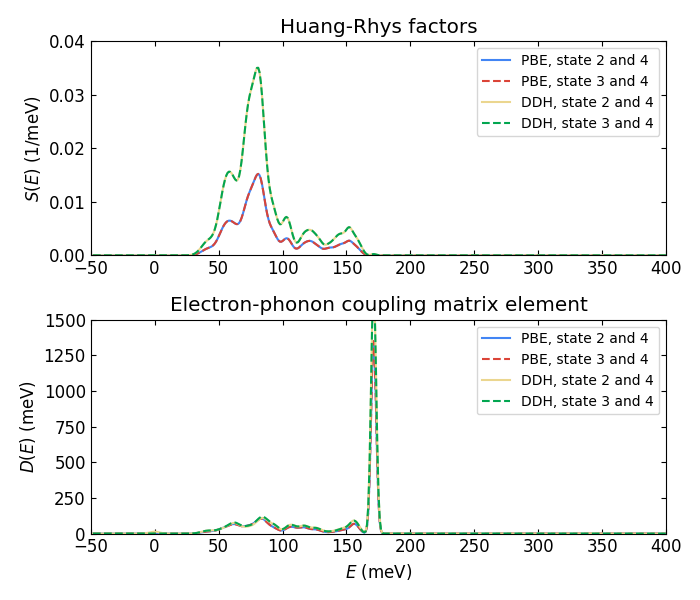

In [16]:
fig, ax = plt.subplots(2, 1, figsize=(7, 6))

colors = [blue, red, goldenrod_yellow, emerald_green]

ax[0].plot(spectral_density_hrf_24_pbe[0], spectral_density_hrf_24_pbe[1],
            color=colors[0], linestyle='-', label=r'PBE, state 2 and 4')
ax[0].plot(spectral_density_hrf_34_pbe[0], spectral_density_hrf_34_pbe[1],
            color=colors[1], linestyle='--', label=r'PBE, state 3 and 4')

ax[0].plot(spectral_density_hrf_24_ddh[0], spectral_density_hrf_24_ddh[1],
            color=colors[2], linestyle='-', label=r'DDH, state 2 and 4')
ax[0].plot(spectral_density_hrf_34_ddh[0], spectral_density_hrf_34_ddh[1],
            color=colors[3], linestyle='--', label=r'DDH, state 3 and 4')

ax[1].plot(
    spectral_density_dH_dq_24_pbe[0],
    spectral_density_dH_dq_24_pbe[1],
    color=colors[0],
    label=r'PBE, state 2 and 4'
)
ax[1].plot(
    spectral_density_dH_dq_34_pbe[0],
    spectral_density_dH_dq_34_pbe[1],
    color=colors[1],
    label=r'PBE, state 3 and 4',
    linestyle='--'
)

ax[1].plot(
    spectral_density_dH_dq_24_ddh[0],
    spectral_density_dH_dq_24_ddh[1],
    color=colors[2],
    label=r'DDH, state 2 and 4'
)
ax[1].plot(
    spectral_density_dH_dq_34_ddh[0],
    spectral_density_dH_dq_34_ddh[1],
    color=colors[3],
    label=r'DDH, state 3 and 4',
    linestyle='--'
)

ax[0].set_title('Huang-Rhys factors')
ax[1].set_title('Electron-phonon coupling matrix element')

for i in range(2):
    ax[i].legend(loc='upper right', fontsize=10)
    ax[1].set_xlabel('$E$ (meV)')
    ax[0].set_ylabel('$S(E)$ (1/meV)')
    ax[1].set_ylabel('$D(E)$ (meV)')
    ax[i].tick_params(direction='in')
    ax[i].yaxis.set_ticks_position('both')
    ax[i].xaxis.set_ticks_position('both')
    ax[0].set_ylim([0, 0.04])
    ax[1].set_ylim([0, 1500])
    ax[i].set_xlim([-50, 400])

fig.tight_layout()
plt.show()

In [17]:
print(sum(dict_nonrad_24_pbe['hr_factors']))
indices = np.argsort(dict_nonrad_24_pbe['hr_factors'])
print('index     freq (meV)      hr_factor     1-2hr_factor')
for ind in indices[-1:-11:-1]:
    print('%4d    % 12.6f    % 10.6f    % 10.6f' % (
        ind, dict_nonrad_24_pbe['freqs'][ind] * hbar / eV * 1e3,
        dict_nonrad_24_pbe['hr_factors'][ind],
        1 - 2 * dict_nonrad_24_pbe['hr_factors'][ind]
        ))


0.5450797388294448
index     freq (meV)      hr_factor     1-2hr_factor
 109       81.694846      0.037906      0.924188
  63       71.679002      0.034629      0.930742
 112       82.419114      0.033424      0.933151
  40       56.970934      0.017054      0.965892
  87       76.795686      0.015555      0.968891
  51       62.529271      0.013985      0.972031
 110       81.694846      0.012201      0.975599
  62       71.679002      0.011146      0.977708
 202      102.433840      0.011115      0.977770
 113       82.419114      0.010759      0.978483


In [18]:
print(sum(dict_nonrad_24_ddh['hr_factors']))
indices = np.argsort(dict_nonrad_24_ddh['hr_factors'])
print('index     freq (meV)      hr_factor     1-2hr_factor')
for ind in indices[-1:-11:-1]:
    print('%4d    % 12.6f    % 10.6f    % 10.6f' % (
        ind, dict_nonrad_24_ddh['freqs'][ind] * hbar / eV * 1e3,
        dict_nonrad_24_ddh['hr_factors'][ind],
        1 - 2 * dict_nonrad_24_ddh['hr_factors'][ind]
        ))

1.2278641760872047
index     freq (meV)      hr_factor     1-2hr_factor
 109       81.694846      0.108266      0.783468
  63       71.679002      0.105428      0.789144
 112       82.419114      0.094331      0.811338
  40       56.970934      0.049138      0.901723
  87       76.795686      0.046961      0.906079
  51       62.529271      0.041625      0.916751
 202      102.433840      0.034186      0.931628
  25       53.388037      0.028296      0.943407
  15       52.154794      0.026346      0.947308
  73       73.766819      0.024944      0.950112


It can be seen that the spectral density $D(E)$ computed between state 2, 4 and that between state 3, 4 are the same, and is dominated by a single peak at 170 meV, which is the localized vibrational mode around the NV center.

In [19]:
# check normalization
print(np.sum(spectral_density_dH_dq_24_pbe[1] * (spectral_density_dH_dq_24_pbe[0][1] - spectral_density_dH_dq_24_pbe[0][0])) * 1e-3 * 1e-3 * constants.eV * constants.eV)
print(np.sum(spectral_density_dH_dq_34_pbe[1] * (spectral_density_dH_dq_34_pbe[0][1] - spectral_density_dH_dq_34_pbe[0][0])) * 1e-3 * 1e-3 * constants.eV * constants.eV)
print(np.sum(dict_nonrad_24_pbe['dH_dq']**2 * constants.hbar / (2 * dict_nonrad_24_pbe['freqs'])))
print(np.sum(dict_nonrad_34_pbe['dH_dq']**2 * constants.hbar / (2 * dict_nonrad_34_pbe['freqs'])))

3.1176733024167244e-40
3.1181202815764537e-40
3.117673302416725e-40
3.118120281576454e-40


In [20]:
# check normalization
print(np.sum(spectral_density_dH_dq_24_ddh[1] * (spectral_density_dH_dq_24_ddh[0][1] - spectral_density_dH_dq_24_ddh[0][0])) * 1e-3 * 1e-3 * constants.eV * constants.eV)
print(np.sum(spectral_density_dH_dq_34_ddh[1] * (spectral_density_dH_dq_34_ddh[0][1] - spectral_density_dH_dq_34_ddh[0][0])) * 1e-3 * 1e-3 * constants.eV * constants.eV)
print(np.sum(dict_nonrad_24_ddh['dH_dq']**2 * constants.hbar / (2 * dict_nonrad_24_ddh['freqs'])))
print(np.sum(dict_nonrad_34_ddh['dH_dq']**2 * constants.hbar / (2 * dict_nonrad_34_ddh['freqs'])))

3.918252928969584e-40
3.9183787726029855e-40
3.9182529289695835e-40
3.918378772602985e-40


## 2. Compute nonradiative rate

We can compute the lineshape function for both the radiative and non-radiative transitions at different temperatures.

In [21]:
temperatures = [0.0, 50, 100, 150, 200, 250, 300, 350, 400]
# temperatures = [78]
zpl_broadenings = np.ones_like(temperatures)*0.18 # meV

rad_lineshapes_pbe = []
rad_lineshapes_ddh = []
nonrad_lineshapes_pbe = []
nonrad_lineshapes_ddh = []

for temp, zpl_broadening in zip(temperatures, zpl_broadenings):
    tmp = nonrad_24_pbe.compute_lineshape_fft(
        dict_nonrad_24_pbe,
        temp=temp,
        sigma=[6, 2],
        zpl_broadening=zpl_broadening,
        lineshape_energy_range=[-2000, 2000],
        lineshape_energy_resolution=40001
    )
    rad_lineshapes_pbe.append(tmp[1])
    print()

    tmp = nonrad_24_ddh.compute_lineshape_fft(
        dict_nonrad_24_ddh,
        temp=temp,
        sigma=[6, 2],
        zpl_broadening=zpl_broadening,
        lineshape_energy_range=[-2000, 2000],
        lineshape_energy_resolution=40001
    )
    rad_lineshapes_ddh.append(tmp)
    print()

    tmp = nonrad_24_pbe.compute_nonrad_lineshape_fft(
        dict_nonrad_24_pbe,
        temp=temp,
        sigma=[6, 2],
        zpl_broadening=zpl_broadening,
        lineshape_energy_range=[-2000, 2000],
        lineshape_energy_resolution=40001
    )
    nonrad_lineshapes_pbe.append(tmp)
    print()

    tmp = nonrad_24_ddh.compute_nonrad_lineshape_fft(
        dict_nonrad_24_ddh,
        temp=temp,
        sigma=[6, 2],
        zpl_broadening=zpl_broadening,
        lineshape_energy_range=[-2000, 2000],
        lineshape_energy_resolution=40001
    )
    nonrad_lineshapes_ddh.append(tmp)
    print()

time_axis range: -2.0678338484646895e-11 to 2.0678338484646895e-11
d_t (s): 1.0338910769554208e-15


/home/svillani/Programs/pypl/pypl/lineshape.py:193: RuntimeWarning: divide by zero encountered in divide
  self.ph_occ = 1 / (np.exp((self.hrf["freqs"] * constants.hbar) / (constants.Boltzmann * self.temp)) - 1)


Energy range (meV): -1999.9999999973306 to 1999.9999999973306
d_E (meV): 0.09999999999968168
Integral check: 999.9999999981516

time_axis range: -2.0678338484646895e-11 to 2.0678338484646895e-11
d_t (s): 1.0338910769554208e-15
Energy range (meV): -1999.9999999973306 to 1999.9999999973306
d_E (meV): 0.09999999999968168
Integral check: 999.9999999981497

time_axis range: -2.0678338484646895e-11 to 2.0678338484646895e-11
d_t (s): 1.0338910769554208e-15


/home/svillani/Programs/pypl/pypl/lineshape.py:328: RuntimeWarning: divide by zero encountered in divide
  self.ph_occ = 1 / (np.exp((self.hrf["freqs"] * constants.hbar) / (constants.Boltzmann * self.temp)) - 1)


Energy range (meV): -1999.9999999973306 to 1999.9999999973306
d_E (meV): 0.09999999999968168
Integral check: 1.9458986208202073e-18

time_axis range: -2.0678338484646895e-11 to 2.0678338484646895e-11
d_t (s): 1.0338910769554208e-15
Energy range (meV): -1999.9999999973306 to 1999.9999999973306
d_E (meV): 0.09999999999968168
Integral check: 2.445581121215086e-18

time_axis range: -2.0678338484646895e-11 to 2.0678338484646895e-11
d_t (s): 1.0338910769554208e-15
Energy range (meV): -1999.9999999973306 to 1999.9999999973306
d_E (meV): 0.09999999999968168
Integral check: 999.9999999981519

time_axis range: -2.0678338484646895e-11 to 2.0678338484646895e-11
d_t (s): 1.0338910769554208e-15
Energy range (meV): -1999.9999999973306 to 1999.9999999973306
d_E (meV): 0.09999999999968168
Integral check: 999.9999999981497

time_axis range: -2.0678338484646895e-11 to 2.0678338484646895e-11
d_t (s): 1.0338910769554208e-15
Energy range (meV): -1999.9999999973306 to 1999.9999999973306
d_E (meV): 0.09999999

<>:48: SyntaxWarning: invalid escape sequence '\m'
<>:48: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_849623/2914682316.py:48: SyntaxWarning: invalid escape sequence '\m'
  ax[1].set_ylabel('$F_{\mathrm{NR}}(\Delta)$ (s$^{-1}$)')


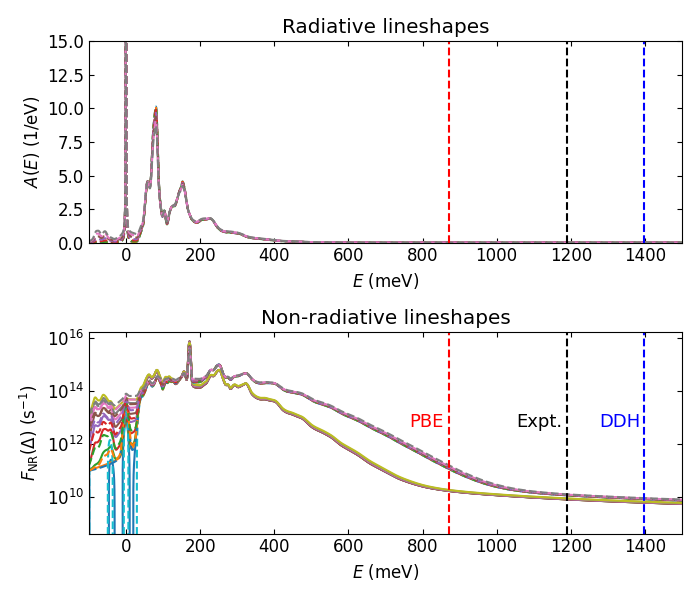

In [22]:
fig, ax = plt.subplots(2, 1, figsize=(7, 6))

for i, temp in enumerate(temperatures):
    ax[0].plot(
        rad_lineshapes_pbe[i][0],
        rad_lineshapes_pbe[i][1],
        linestyle='-',
        label='PBE, T = %.0f K' % (temp)
    )
for i, temp in enumerate(temperatures):
    ax[0].plot(
        rad_lineshapes_ddh[i][0],
        rad_lineshapes_ddh[i][1],
        linestyle='--',
        label='DDH, T = %.0f K' % (temp)
    )

for i, temp in enumerate(temperatures):
    ax[1].plot(
        nonrad_lineshapes_pbe[i][0],
        nonrad_lineshapes_pbe[i][1] * 2 * np.pi / hbar,
        linestyle='-',
        label='PBE, T = %.0f K' % (temp)
    )
for i, temp in enumerate(temperatures):
    ax[1].plot(
        nonrad_lineshapes_ddh[i][0],
        nonrad_lineshapes_ddh[i][1] * 2 * np.pi / hbar,
        linestyle='--',
        label='DDH, T = %.0f K' % (temp)
    )

ax[0].axvline(x=adiabatic_energy, color='black', linestyle='--')
ax[1].axvline(x=adiabatic_energy, color='black', linestyle='--')

ax[0].axvline(x=adiabatic_energy_pbe, color='red', linestyle='--')
ax[1].axvline(x=adiabatic_energy_pbe, color='red', linestyle='--')

ax[0].axvline(x=adiabatic_energy_ddh, color='blue', linestyle='--')
ax[1].axvline(x=adiabatic_energy_ddh, color='blue', linestyle='--')

ax[0].set_title('Radiative lineshapes')
ax[1].set_title('Non-radiative lineshapes')

for i in range(2):
    ax[i].set_xlabel('$E$ (meV)')
    ax[0].set_ylabel('$A(E)$ (1/eV)')
    ax[1].set_ylabel('$F_{\mathrm{NR}}(\Delta)$ (s$^{-1}$)')
    ax[i].tick_params(direction='in')
    ax[i].yaxis.set_ticks_position('both')
    ax[i].xaxis.set_ticks_position('both')
    ax[0].set_ylim([0, 15])
    ax[i].set_xlim([-100, 1500])
    ax[1].set_yscale('log')

ax[1].text(0.54, 0.6, 'PBE', transform=ax[1].transAxes, ha='left', va='top', fontsize=13, color='red')
ax[1].text(0.72, 0.6, 'Expt.', transform=ax[1].transAxes, ha='left', va='top', fontsize=13, color='k')
ax[1].text(0.86, 0.6, 'DDH', transform=ax[1].transAxes, ha='left', va='top', fontsize=13, color='blue')

fig.tight_layout()
plt.show()

By comparing the radiative and non-radiative lineshapes, we can see that the non-radiative lineshape has a signature of right shifted by about 170 meV, originating from the strong nonadiabatic coupling associated with the 170 meV local phonon mode.

We can compute the nonradiative rate at the corresponding nonadiabatic transition energy.

In [23]:
g = 1

rate_non_rad_pbe = []
print('Nonradiative, all modes, PBE, singlets')
for i, temp in enumerate(temperatures):
    for energy, lineshape in zip(*nonrad_lineshapes_pbe[i]):
        if abs(energy - adiabatic_energy_pbe) < 0.01:
            rate_non_rad_pbe.append(lineshape * 2 * np.pi / hbar * g)
            print('T = %3.f K, Energy = %.12e meV, rate = %.12e 1/s' % (
                temp, energy, lineshape * 2 * np.pi / hbar * g)
            )
# =================================================================================
print()

rate_non_rad_ddh = []
print('Nonradiative, all modes, DDH, singlets')
for i, temp in enumerate(temperatures):
    for energy, lineshape in zip(*nonrad_lineshapes_ddh[i]):
        if abs(energy - adiabatic_energy_ddh) < 0.01:
            rate_non_rad_ddh.append(lineshape * 2 * np.pi / hbar * g)
            print('T = %3.f K, Energy = %.12e meV, rate = %.12e 1/s' % (
                temp,energy, lineshape * 2 * np.pi / hbar * g)
            )

Nonradiative, all modes, PBE, singlets
T =   0 K, Energy = 8.709999999988e+02 meV, rate = 1.717292694931e+10 1/s
T =  50 K, Energy = 8.709999999988e+02 meV, rate = 1.717548627438e+10 1/s
T = 100 K, Energy = 8.709999999988e+02 meV, rate = 1.718173992939e+10 1/s
T = 150 K, Energy = 8.709999999988e+02 meV, rate = 1.722888086252e+10 1/s
T = 200 K, Energy = 8.709999999988e+02 meV, rate = 1.735422066346e+10 1/s
T = 250 K, Energy = 8.709999999988e+02 meV, rate = 1.757376895234e+10 1/s
T = 300 K, Energy = 8.709999999988e+02 meV, rate = 1.789164736232e+10 1/s
T = 350 K, Energy = 8.709999999988e+02 meV, rate = 1.830809940734e+10 1/s
T = 400 K, Energy = 8.709999999988e+02 meV, rate = 1.882196342225e+10 1/s

Nonradiative, all modes, DDH, singlets
T =   0 K, Energy = 1.396999999998e+03 meV, rate = 8.510609041765e+09 1/s
T =  50 K, Energy = 1.396999999998e+03 meV, rate = 8.511667174278e+09 1/s
T = 100 K, Energy = 1.396999999998e+03 meV, rate = 8.515105059057e+09 1/s
T = 150 K, Energy = 1.39699999999

[1.71729269e+10 1.71754863e+10 1.71817399e+10 1.72288809e+10
 1.73542207e+10 1.75737690e+10 1.78916474e+10 1.83080994e+10
 1.88219634e+10]
[8.51060904e+09 8.51166717e+09 8.51510506e+09 8.53848505e+09
 8.59722354e+09 8.69695265e+09 8.83842093e+09 9.02058887e+09
 9.24136325e+09]


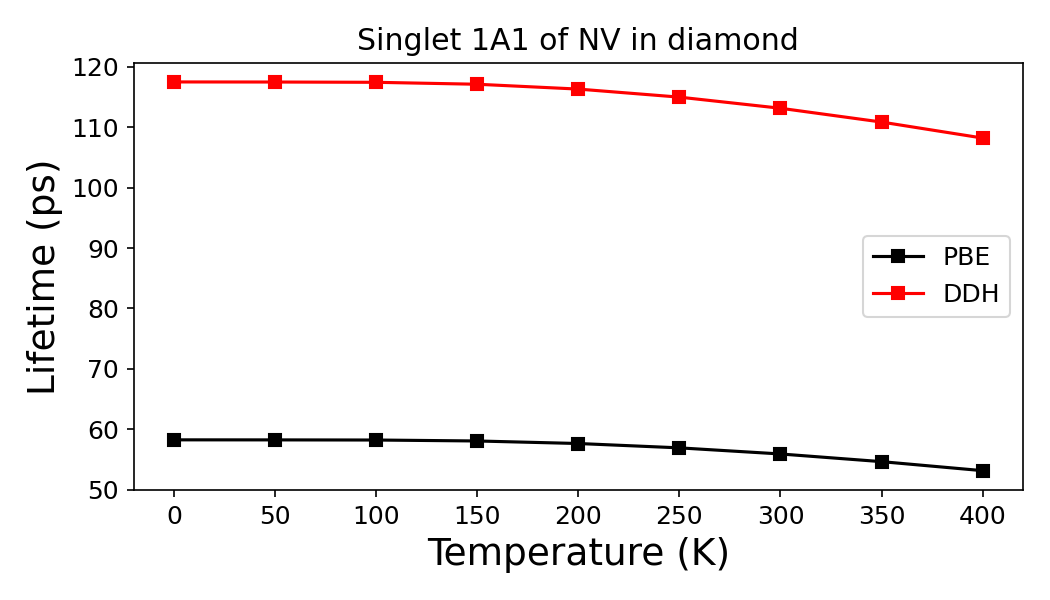

In [24]:
fig, ax = plt.subplots(1, 1, figsize=(7, 4), dpi=150)

rate_non_rad_pbe = np.array(rate_non_rad_pbe)
rate_non_rad_ddh = np.array(rate_non_rad_ddh)
lifetimes_pbe = 1/( rate_non_rad_pbe) * 1e+12
lifetimes_ddh = 1/( rate_non_rad_ddh) * 1e+12
print(rate_non_rad_pbe)
print(rate_non_rad_ddh)
ax.plot(temperatures,lifetimes_pbe,c='k',marker='s',label='PBE')
ax.plot(temperatures,lifetimes_ddh,c='r',marker='s',label='DDH')
ax.set_xlabel('Temperature (K)',fontsize=18)
ax.set_ylabel('Lifetime (ps)',fontsize=18)
ax.set_title('Singlet 1A1 of NV in diamond')
ax.legend()
fig.tight_layout()
plt.show()

<>:36: SyntaxWarning: invalid escape sequence '\G'
<>:84: SyntaxWarning: invalid escape sequence '\m'
<>:36: SyntaxWarning: invalid escape sequence '\G'
<>:84: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_849623/3832741811.py:36: SyntaxWarning: invalid escape sequence '\G'
  ax[0].set_ylabel('$\Gamma_\mathrm{NR}$ (GHz)')
/tmp/ipykernel_849623/3832741811.py:84: SyntaxWarning: invalid escape sequence '\m'
  ax[3].set_ylabel('$F_\mathrm{NR}(\Delta)$ (s$^{-1}$)')
/tmp/ipykernel_849623/3832741811.py:100: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


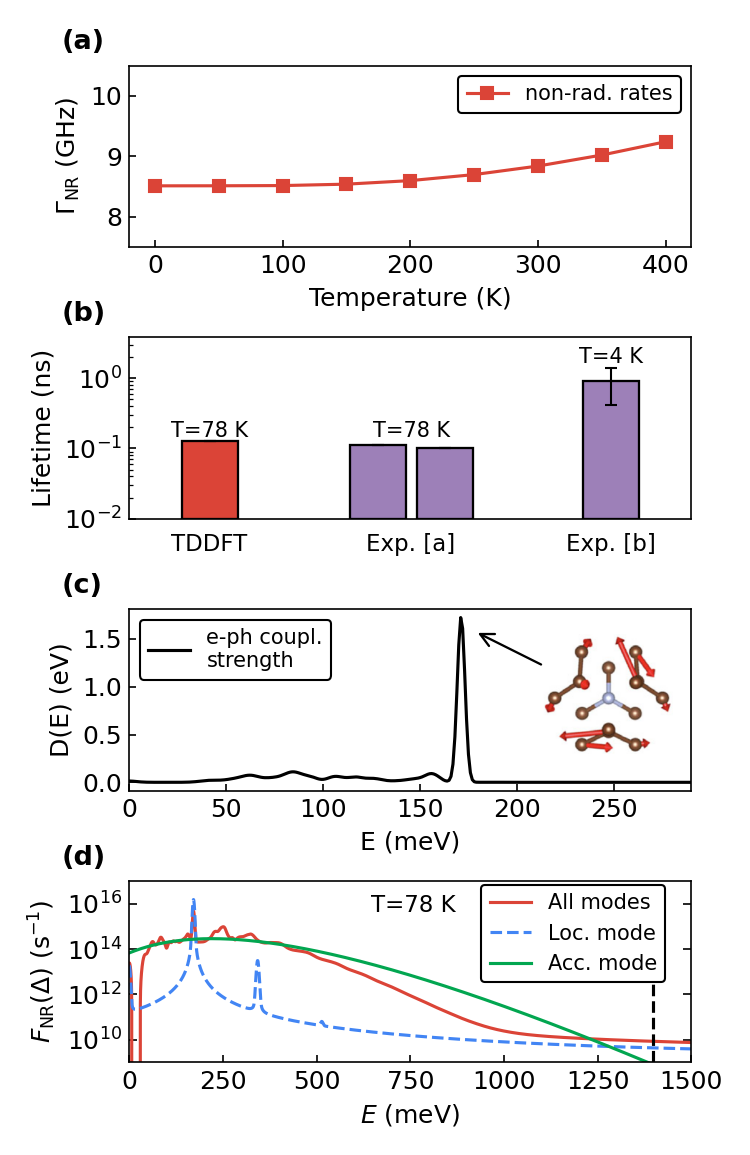

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.image as mpimg
from matplotlib.patches import ConnectionPatch
# -----------------------------
rate_non_rad_pbe = np.array(rate_non_rad_pbe)
rate_non_rad_ddh = np.array(rate_non_rad_ddh)

lifetimes_pbe = 1 / rate_non_rad_pbe * 1e9   # ns
lifetimes_ddh = 1 / rate_non_rad_ddh * 1e9   # ns

acosta = 900e-12          # s
ulbritch_1 = 102.3e-12    # s
ulbritch_2 = 92.1e-12     # s
TDDFT_DDH = 8.51236619e+09   # Hz
TDDFT_PBE = 1.71766827e+10   # Hz
DFT_ping  = 4.82e+8          # Hz

lifetime = np.array([1 / TDDFT_PBE, 1 / TDDFT_DDH, ulbritch_1, ulbritch_2, acosta]) * 1e9 # ns

data = np.load("NVD_singlets_locmode_T78K.npz")
E_loc  = data["x"]
LS_loc = data["y"]

data = np.load("NVD_singlets_effmode_T78K.npz")
E_eff  = data["x"]
LS_eff = data["y"]
# -----------------------------
fig, ax = plt.subplots(4, 1, figsize=(5*1.0, 7*1.1), dpi=150)
ax=ax.ravel()
#
ax[0].plot(temperatures, rate_non_rad_ddh*1e-9, c=red, marker='s', label='non-rad. rates')
ax[0].set_xlabel('Temperature (K)')
ax[0].set_ylabel('$\Gamma_\mathrm{NR}$ (GHz)')
ax[0].set_ylim(ymin=7.5,ymax=10.5)
ax[0].set_yticks([8,9,10])
ax[0].tick_params(direction='in')
ax[0].legend(fontsize=10,edgecolor='k',framealpha=1.0, loc='best')
#
x = [1.0, 1.25, 1.46, 1.543, 1.75]
w = 0.07
err = np.zeros_like(lifetime, dtype=float)
err[4] = 0.5
ax[1].bar(x,lifetime,width=w,edgecolor='k',facecolor=[blue,red,deep_violet,deep_violet,deep_violet],
          linewidth=1.1,bottom=1e-2,yerr=err,capsize=3,error_kw={'elinewidth': 1.0, 'ecolor': 'k'})
ax[1].set_ylabel('Lifetime (ns)')
ax[1].set_yscale('log')
ax[1].set_ylim(1e-2, 3.8)
ax[1].tick_params(axis='both', which='both', direction='in')
ax[1].tick_params(axis='x', length=0, pad=7)
ax[1].set_xticks([1.0, 1.25, 1.5, 1.75],['PBE', 'TDDFT', 'Exp. [a]', 'Exp. [b]'],fontsize=11)
ax[1].text(x[1], 0.25, 'T=78 K', ha='center', va='top', fontsize=10)
ax[1].text(np.mean(x[2:4]), 0.25, 'T=78 K', ha='center', va='top', fontsize=10)
ax[1].text(x[4], 2.8, 'T=4 K', ha='center', va='top', fontsize=10)
ax[1].set_xlim(xmin=1.15, xmax=1.85)
# 
ax[2].plot(spectral_density_dH_dq_24_ddh[0],spectral_density_dH_dq_24_ddh[1]/1000,
           color='k',ls='-',label='e-ph coupl.\nstrength')
ax[2].set_xlabel('E (meV)')
ax[2].set_ylabel('D(E) (eV)')
ax[2].tick_params(direction='in')
ax[2].set_yticks([0.0,0.5,1.0,1.5])
ax[2].set_xlim([0, 290])
ax[2].legend(fontsize=10,edgecolor='k',framealpha=1.0, loc='upper left')
img = mpimg.imread("loc_vib_mode.png")
axins = inset_axes(ax[2],width=1.5,height=.8,loc="center",bbox_to_anchor=(0.7,0.38,0.3,0.3),
                   bbox_transform=ax[2].transAxes,borderpad=0)
axins.imshow(img)
axins.axis("off")
arrow = ConnectionPatch(xyA=(0.0,0.75),coordsA=axins.transAxes,xyB=(0.62,0.87),coordsB=ax[2].transAxes,
                        arrowstyle="->",mutation_scale=16,lw=1.1,color="k",clip_on=False)
fig.add_artist(arrow)
#
ax[3].plot(nonrad_lineshapes_ddh[0][0], nonrad_lineshapes_ddh[0][1]*2*np.pi/hbar, color=red,linestyle='-',label='All modes')
ax[3].plot(E_loc, LS_loc, color=blue, linestyle='--', label='Loc. mode')
ax[3].plot(E_eff, LS_eff, color=emerald_green, linestyle='-', label='Acc. mode')
ax[3].set_yscale('log')
ax[3].set_ylim(bottom=1e9, top=1e17)
ax[3].tick_params(axis='y', which='major', direction='in', length=4, right=True)
ax[3].set_yticks([1e10, 1e12, 1e14, 1e16])
ax[3].set_xlabel('$E$ (meV)')
ax[3].set_ylabel('$F_\mathrm{NR}(\Delta)$ (s$^{-1}$)')
ax[3].tick_params(axis='both', which='both', direction='in')
ax[3].text(0.43, 0.93, 'T=78 K', transform=ax[3].transAxes, ha='left', va='top', fontsize=11)
ax[3].legend(fontsize=10,edgecolor='k',framealpha=1.0, loc='center', bbox_to_anchor=(0.79,0.71))
ax[3].set_xlim([-0, 1500])
ax[3].axvline(x=adiabatic_energy_ddh, color='black', linestyle='--')
#
labels = ['(a)', '(b)', '(c)', '(d)']
for i, label in enumerate(labels):
    ax[i].text(
        -0.12, 1.2, label,
        transform=ax[i].transAxes,
        ha='left', va='top',
        fontsize=13, fontweight='bold'
    )

fig.tight_layout()
fig.subplots_adjust(hspace=0.5)
plt.show()

### Comparison PBE vs DDH

<>:35: SyntaxWarning: invalid escape sequence '\G'
<>:59: SyntaxWarning: invalid escape sequence '\m'
<>:35: SyntaxWarning: invalid escape sequence '\G'
<>:59: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_849623/3480198886.py:35: SyntaxWarning: invalid escape sequence '\G'
  ax[0].set_ylabel('$\Gamma_\mathrm{NR}$ (GHz)')
/tmp/ipykernel_849623/3480198886.py:59: SyntaxWarning: invalid escape sequence '\m'
  ax[2].set_ylabel('$F_\mathrm{NR}(\Delta)$ (s$^{-1}$)')


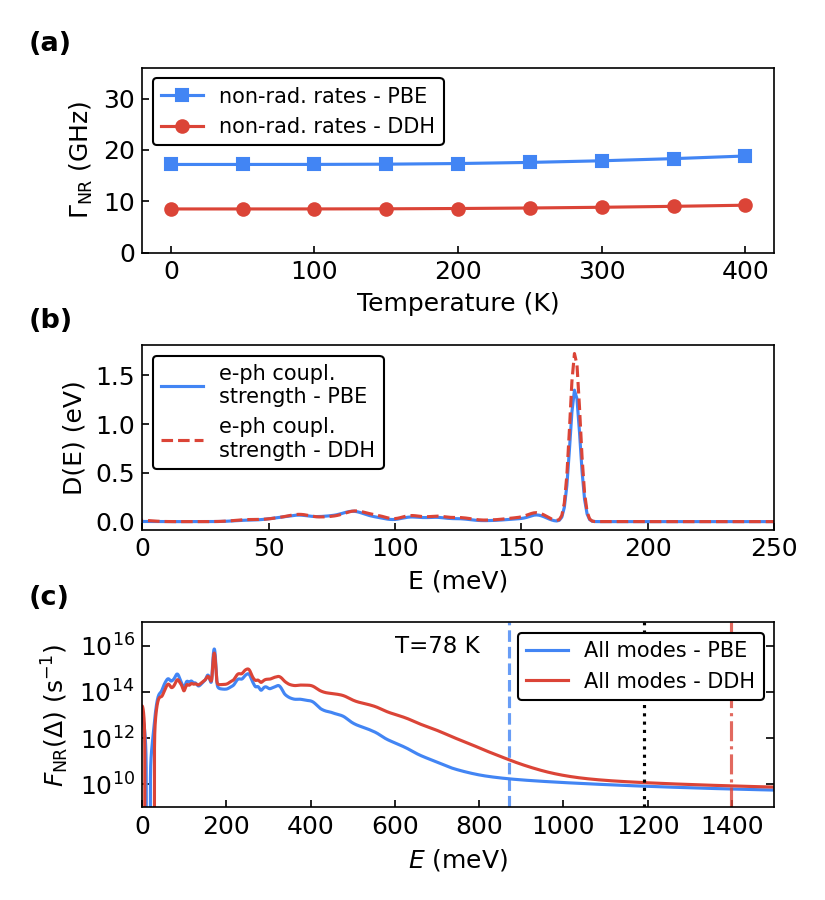

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter

# -----------------------------
rate_non_rad_pbe = np.array(rate_non_rad_pbe)
rate_non_rad_ddh = np.array(rate_non_rad_ddh)

lifetimes_pbe = 1 / rate_non_rad_pbe * 1e9   # ns
lifetimes_ddh = 1 / rate_non_rad_ddh * 1e9   # ns

acosta = 900e-12          # s
ulbritch_1 = 102.3e-12    # s
ulbritch_2 = 92.1e-12     # s
TDDFT_DDH = 8.51236619e+09   # Hz
TDDFT_PBE = 1.71766827e+10   # Hz
DFT_ping  = 4.82e+8          # Hz

NRTR = np.array([1 / TDDFT_PBE, 1 / TDDFT_DDH, ulbritch_1, ulbritch_2, acosta]) * 1e9 # ns

data = np.load("NVD_singlets_locmode_T78K.npz")
E_loc  = data["x"]
LS_loc = data["y"]

data = np.load("NVD_singlets_effmode_T78K.npz")
E_eff  = data["x"]
LS_eff = data["y"]
# -----------------------------
fig, ax = plt.subplots(3, 1, figsize=(5.5, 6), dpi=150)
ax=ax.ravel()
# #
ax[0].plot(temperatures, rate_non_rad_pbe*1e-9, c=blue, marker='s', label='non-rad. rates - PBE')
ax[0].plot(temperatures, rate_non_rad_ddh*1e-9, c=red, marker='o', label='non-rad. rates - DDH')
ax[0].set_xlabel('Temperature (K)')
ax[0].set_ylabel('$\Gamma_\mathrm{NR}$ (GHz)')
ax[0].set_ylim(ymin=0.0,ymax=36.0)
ax[0].set_yticks([0,10,20,30])
ax[0].tick_params(direction='in')
ax[0].legend(fontsize=10,edgecolor='k',framealpha=1.0, loc='upper left')
# #
ax[1].plot(spectral_density_dH_dq_24_pbe[0],spectral_density_dH_dq_24_pbe[1]/1000,
        color=blue,ls='-',label='e-ph coupl.\nstrength - PBE')
ax[1].plot(spectral_density_dH_dq_24_ddh[0],spectral_density_dH_dq_24_ddh[1]/1000,
        color=red,ls='--',label='e-ph coupl.\nstrength - DDH')
ax[1].set_xlabel('E (meV)')
ax[1].set_ylabel('D(E) (eV)')
ax[1].tick_params(direction='in')
ax[1].set_yticks([0.0,0.5,1.0,1.5])
ax[1].set_xlim([0, 250])
ax[1].legend(fontsize=10,edgecolor='k',framealpha=1.0, loc='upper left')
#
ax[2].plot(nonrad_lineshapes_pbe[0][0], nonrad_lineshapes_pbe[0][1]*2*np.pi/hbar, color=blue,linestyle='-',label='All modes - PBE')
ax[2].plot(nonrad_lineshapes_ddh[0][0], nonrad_lineshapes_ddh[0][1]*2*np.pi/hbar, color=red,linestyle='-',label='All modes - DDH')
ax[2].set_yscale('log')
ax[2].set_ylim(bottom=1e9, top=1e17)
ax[2].tick_params(axis='y', which='major', direction='in', length=4, right=True)
ax[2].set_yticks([1e10, 1e12, 1e14, 1e16])
ax[2].set_xlabel('$E$ (meV)')
ax[2].set_ylabel('$F_\mathrm{NR}(\Delta)$ (s$^{-1}$)')
ax[2].tick_params(axis='both', which='both', direction='in')
ax[2].text(0.4, 0.93, 'T=78 K', transform=ax[2].transAxes, ha='left', va='top', fontsize=11)
ax[2].legend(fontsize=10,edgecolor='k',framealpha=1.0,loc='upper right')
ax[2].set_xlim([-0, 1500])
ax[2].axvline(x=adiabatic_energy, color='black', linestyle='dotted')
ax[2].axvline(x=adiabatic_energy_pbe, color=blue, alpha=0.8, linestyle='--')
ax[2].axvline(x=adiabatic_energy_ddh, color=red, alpha=0.8, linestyle='-.')
#
labels = ['(a)', '(b)', '(c)'] 
for i, label in enumerate(labels):
    ax[i].text(
        -0.18, 1.2, label,
        transform=ax[i].transAxes,
        ha='left', va='top',
        fontsize=13, fontweight='bold'
    )

fig.tight_layout()
fig.subplots_adjust(hspace=0.5)
plt.show()

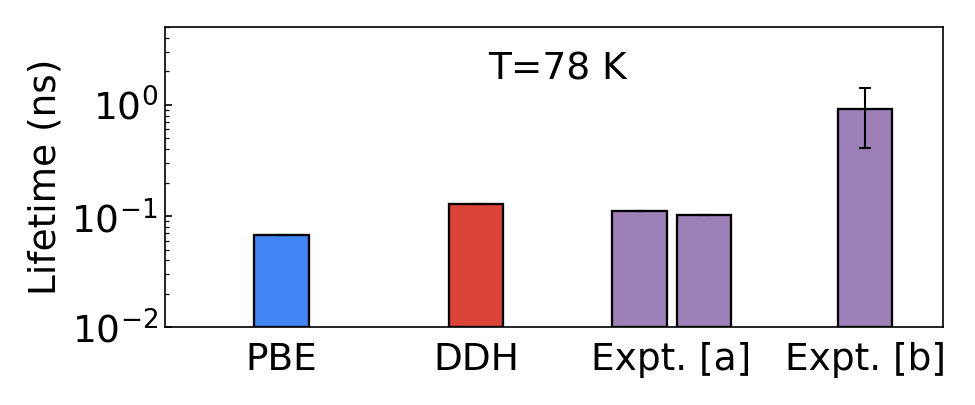

In [27]:
rate_non_rad_pbe = np.array(rate_non_rad_pbe)
rate_non_rad_ddh = np.array(rate_non_rad_ddh)

lifetimes_pbe = 1 / rate_non_rad_pbe * 1e9   # ns
lifetimes_ddh = 1 / rate_non_rad_ddh * 1e9   # ns

acosta = 900e-12          # s
ulbritch_1 = 102.3e-12    # s
ulbritch_2 = 92.1e-12     # s
TDDFT_DDH = 8.51236619e+09   # Hz
TDDFT_PBE = 1.71766827e+10   # Hz
DFT_ping  = 4.82e+8          # Hz

lifetime = np.array([1 / TDDFT_PBE, 1 / TDDFT_DDH, ulbritch_1, ulbritch_2, acosta]) * 1e9 # ns

fig, ax = plt.subplots(1, 1, figsize=(6.5, 2.7), dpi=150)

x = [1.0, 1.25, 1.46, 1.543, 1.75]
w = 0.07
err = np.zeros_like(lifetime, dtype=float)
err[4] = 0.5
ax.bar(x,lifetime,width=w,edgecolor='k',facecolor=[blue,red,deep_violet,deep_violet,deep_violet],
          linewidth=1.1,bottom=1e-2,yerr=err,capsize=3,error_kw={'elinewidth': 1.0, 'ecolor': 'k'})
ax.set_ylabel('Lifetime (ns)',size=18)
ax.set_yscale('log')
ax.set_ylim(1e-2, 5.0)
ax.tick_params(axis='both', which='both', direction='in',labelsize=18)
ax.tick_params(axis='x', length=0, pad=7)
ax.set_xticks([1.0, 1.25, 1.5, 1.75],['PBE', 'DDH', 'Expt. [a]', 'Expt. [b]'],fontsize=18)
ax.text(np.mean([x[1],x[2]]),3,'T=78 K',ha='center',va='top',fontsize=18)
ax.set_xlim(xmin=0.85, xmax=1.85)
fig.tight_layout()
plt.show()